In [1]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import os
import torch 
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
from torch.autograd.variable import Variable
import matplotlib.pyplot as plt

In [2]:
torch.manual_seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cuda


In [3]:
TRAIN_HIGH = "/kaggle/input/competitions/plant-leaves-super-resolution-challenge/train_High_Resolution"
TRAIN_LOW = "//kaggle/input/competitions/plant-leaves-super-resolution-challenge/train_Low_Resolution"
TEST = "/kaggle/input/competitions/plant-leaves-super-resolution-challenge/test_Low_Resolution"
VGG

In [4]:
print("number of high res train images: ", len(os.listdir(TRAIN_HIGH)))
print("number of low res train images: ", len(os.listdir(TRAIN_LOW)))
print("number of low res test images: ", len(os.listdir(TEST)))

number of high res train images:  1642
number of low res train images:  1642
number of low res test images:  495


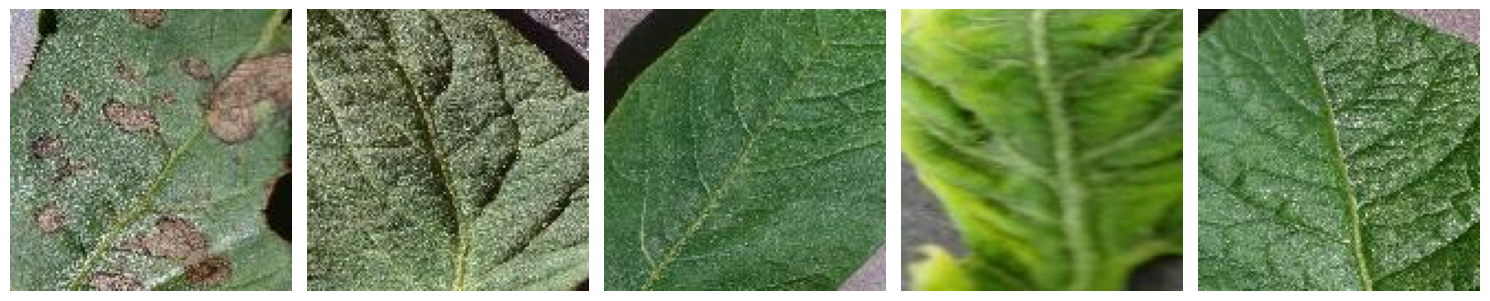

In [5]:
from PIL import Image

files = os.listdir(TRAIN_HIGH)

fig, ax = plt.subplots(1, 5, figsize=(15, 5))

for i in range(5):
    img_path = os.path.join(TRAIN_HIGH, files[i])  
    img = Image.open(img_path)                     
    
    ax[i].imshow(img)
    ax[i].axis('off')

plt.tight_layout()
plt.show()

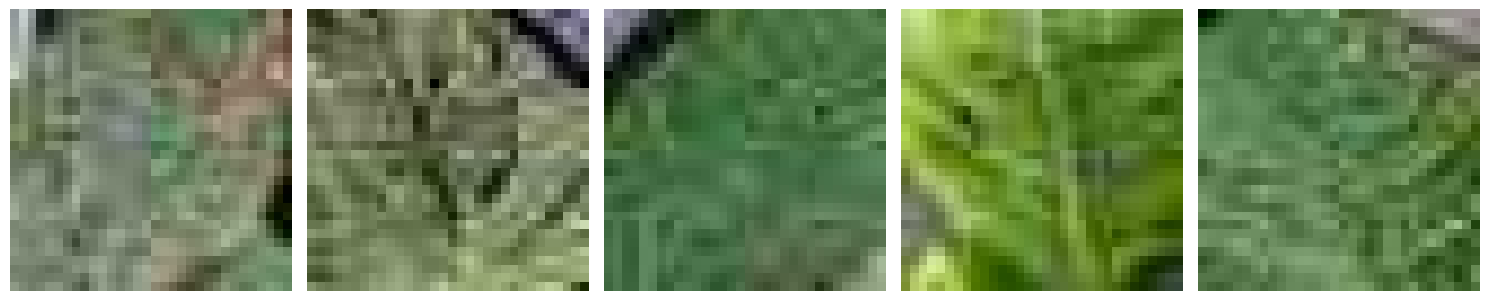

In [6]:
files = os.listdir(TRAIN_LOW)

fig, ax = plt.subplots(1, 5, figsize=(15, 5))

for i in range(5):
    img_path = os.path.join(TRAIN_LOW, files[i])  
    img = Image.open(img_path)                     
    
    ax[i].imshow(img)
    ax[i].axis('off')

plt.tight_layout()
plt.show()

In [7]:
from torch.utils.data import Dataset, DataLoader

class SRDataset(Dataset):
    def __init__(self, lr_dir, hr_dir, transform=None):
        self.lr_dir = lr_dir
        self.hr_dir = hr_dir
        
        self.lr_images = sorted(os.listdir(lr_dir))
        self.hr_images = sorted(os.listdir(hr_dir))
                
        self.transform = transform

    def __len__(self):
        return len(self.lr_images)

    def __getitem__(self, idx):
        lr_path = os.path.join(self.lr_dir, self.lr_images[idx])
        hr_path = os.path.join(self.hr_dir, self.hr_images[idx])

        lr_img = Image.open(lr_path).convert("RGB")
        hr_img = Image.open(hr_path).convert("RGB")

        if self.transform:
            lr_img = self.transform(lr_img)
            hr_img = self.transform(hr_img)

        return lr_img, hr_img

In [8]:
transform = transforms.ToTensor()

In [9]:
from torch.utils.data import random_split

full_dataset = SRDataset(lr_dir=TRAIN_LOW, hr_dir=TRAIN_HIGH, transform=transform)

val_size = int(0.1 * len(full_dataset))
train_size = len(full_dataset) - val_size  

train_dataset, val_dataset = random_split(full_dataset, [train_size, val_size])

train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=16, shuffle=False, num_workers=2)

In [10]:
lr, hr = train_dataset[0]
print(lr.shape, hr.shape)

torch.Size([3, 32, 32]) torch.Size([3, 128, 128])


In [11]:
class ResidualBlock(nn.Module):
    def __init__(self, channels):
        super(ResidualBlock, self).__init__()
        self.block = nn.Sequential(
            nn.Conv2d(channels, channels, 3, padding=1),
            nn.BatchNorm2d(channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(channels, channels, 3, padding=1),
            nn.BatchNorm2d(channels)
        )

    def forward(self, x):
        return x + self.block(x)


class Generator(nn.Module):
    def __init__(self):
        super(Generator, self).__init__()

        self.conv1 = nn.Sequential(
            nn.Conv2d(3, 64, 9, padding=4),
            nn.ReLU(inplace=True)
        )
        self.res_blocks = nn.Sequential(
            ResidualBlock(64),
            ResidualBlock(64),
            ResidualBlock(64),
            ResidualBlock(64),
            ResidualBlock(64),
        )
        self.up1 = nn.Sequential(
            nn.Upsample(scale_factor=2, mode='bilinear', align_corners=False),
            nn.Conv2d(64, 64, 3, padding=1),
            nn.ReLU(inplace=True)
        )
        self.up2 = nn.Sequential(
            nn.Upsample(scale_factor=2, mode='bilinear', align_corners=False),
            nn.Conv2d(64, 64, 3, padding=1),
            nn.ReLU(inplace=True)
        )
        self.conv_out = nn.Conv2d(64, 3, 9, padding=4)

    def forward(self, x):
        x1 = self.conv1(x)
        x = self.res_blocks(x1)
        x = x + x1
        x = self.up1(x)
        x = self.up2(x)
        x = self.conv_out(x)
        return x

In [12]:
G = Generator().to(device)
lr_batch, hr_batch = next(iter(train_loader))

lr_batch = lr_batch.to(device)
hr_batch = hr_batch.to(device)

out = G(lr_batch)
print(out.shape)

torch.Size([16, 3, 128, 128])


In [13]:
class Discriminator(nn.Module):
    def __init__(self):
        super(Discriminator, self).__init__()

        self.model = nn.Sequential(
            nn.Conv2d(6, 32, 4, stride=2, padding=1),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(32, 64, 4, stride=2, padding=1),
            nn.BatchNorm2d(64),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(64, 128, 4, stride=2, padding=1),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(128, 1, 4, stride=1, padding=1),
        )

    def forward(self, x):
        return self.model(x)

In [14]:
import torch.nn.functional as F

D = Discriminator().to(device)
lr_upsampled = F.interpolate(lr_batch, size=(128, 128), mode='bilinear', align_corners=False)

fake_hr = G(lr_batch)

real_input = torch.cat([lr_upsampled, hr_batch], dim=1)
real_output = D(real_input)
print(real_output.shape)

fake_input = torch.cat([lr_upsampled, fake_hr.detach()], dim=1)  
fake_output = D(fake_input)
print(fake_output.shape)

torch.Size([16, 1, 15, 15])
torch.Size([16, 1, 15, 15])


In [15]:
criterion = nn.BCEWithLogitsLoss()
l1 = nn.L1Loss()

d_optimizer = torch.optim.Adam(D.parameters(), lr=0.0001, betas=(0.5, 0.999))
g_optimizer = torch.optim.Adam(G.parameters(), lr=0.0002, betas=(0.5, 0.999))
# num_epochs = 30
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(g_optimizer, mode='min', patience=5, factor=0.5)


In [16]:
num_pretrain_epochs = 50

for epoch in range(num_pretrain_epochs):
    G.train()
    for lr_imgs, hr_imgs in train_loader:
        lr_imgs = lr_imgs.to(device)
        hr_imgs = hr_imgs.to(device)

        g_optimizer.zero_grad()
        fake_hr = G(lr_imgs)
        g_loss = l1(fake_hr, hr_imgs)
        g_loss.backward()
        g_optimizer.step()

    G.eval()
    val_mae = 0
    with torch.no_grad():
        for lr_imgs, hr_imgs in val_loader:
            lr_imgs = lr_imgs.to(device)
            hr_imgs = hr_imgs.to(device)
            fake_hr = G(lr_imgs)
            val_mae += torch.mean(torch.abs(fake_hr * 255 - hr_imgs * 255)).item()
    val_mae /= len(val_loader)
    scheduler.step(val_mae)

    print(f"Epoch [{epoch+1}/{num_pretrain_epochs}], L1 Loss: {g_loss.item():.4f}, MAE: {val_mae:.4f}")

Epoch [1/50], L1 Loss: 0.1183, MAE: 22.6734
Epoch [2/50], L1 Loss: 0.0908, MAE: 27.2779
Epoch [3/50], L1 Loss: 0.0857, MAE: 18.4679
Epoch [4/50], L1 Loss: 0.0827, MAE: 19.4257
Epoch [5/50], L1 Loss: 0.0778, MAE: 19.5313
Epoch [6/50], L1 Loss: 0.0753, MAE: 18.3258
Epoch [7/50], L1 Loss: 0.0920, MAE: 19.8608
Epoch [8/50], L1 Loss: 0.0684, MAE: 19.4736
Epoch [9/50], L1 Loss: 0.0773, MAE: 17.6842
Epoch [10/50], L1 Loss: 0.0912, MAE: 20.7181
Epoch [11/50], L1 Loss: 0.0779, MAE: 19.4543
Epoch [12/50], L1 Loss: 0.0816, MAE: 17.7206
Epoch [13/50], L1 Loss: 0.0780, MAE: 19.0323
Epoch [14/50], L1 Loss: 0.0617, MAE: 18.4598
Epoch [15/50], L1 Loss: 0.0676, MAE: 17.8046
Epoch [16/50], L1 Loss: 0.0934, MAE: 17.2554
Epoch [17/50], L1 Loss: 0.0719, MAE: 17.5587
Epoch [18/50], L1 Loss: 0.0655, MAE: 17.2509
Epoch [19/50], L1 Loss: 0.0668, MAE: 17.1940
Epoch [20/50], L1 Loss: 0.0535, MAE: 17.2530
Epoch [21/50], L1 Loss: 0.0692, MAE: 17.4718
Epoch [22/50], L1 Loss: 0.0770, MAE: 17.4039
Epoch [23/50], L1 L

In [17]:
for epoch in range(5):
    D.train()
    for lr_imgs, hr_imgs in train_loader:
        lr_imgs = lr_imgs.to(device)
        hr_imgs = hr_imgs.to(device)
        lr_up = F.interpolate(lr_imgs, size=(128, 128), mode='bilinear', align_corners=False)

        d_optimizer.zero_grad()

        with torch.no_grad():
            fake_hr = G(lr_imgs)

        real_input = torch.cat([lr_up, hr_imgs], dim=1)
        fake_input = torch.cat([lr_up, fake_hr], dim=1)

        d_loss = (criterion(D(real_input), torch.ones_like(D(real_input))) +
                  criterion(D(fake_input), torch.zeros_like(D(fake_input)))) / 2

        d_loss.backward()
        d_optimizer.step()

    print(f"Epoch [{epoch+1}/5], D Loss: {d_loss.item():.4f}")

Epoch [1/5], D Loss: 0.2886
Epoch [2/5], D Loss: 0.0559
Epoch [3/5], D Loss: 0.0278
Epoch [4/5], D Loss: 0.0154
Epoch [5/5], D Loss: 0.0076


In [20]:
import torchvision.models as models

VGG_PATH = "/kaggle/input/competitions/plant-leaves-super-resolution-challenge/vgg19_weights.pth"

vgg = models.vgg19(weights=None)  
vgg.load_state_dict(torch.load(VGG_PATH, map_location=device))
vgg_features = nn.Sequential(*list(vgg.features)[:18]).to(device).eval()

for param in vgg_features.parameters():
    param.requires_grad = False  

def perceptual_loss(fake_hr, real_hr):
    return nn.L1Loss()(vgg_features(fake_hr), vgg_features(real_hr))

In [23]:
lambda_pixel = 100
lambda_vgg = 0.1

g_vgg_loss = perceptual_loss(fake_hr, hr_imgs)

for epoch in range(50):
    G.train()
    D.train()
    for lr_imgs, hr_imgs in train_loader:
        lr_imgs = lr_imgs.to(device)
        hr_imgs = hr_imgs.to(device)
        lr_up = F.interpolate(lr_imgs, size=(128, 128), mode='bilinear', align_corners=False)

        d_optimizer.zero_grad()
        fake_hr = G(lr_imgs)
        real_input = torch.cat([lr_up, hr_imgs], dim=1)
        fake_input = torch.cat([lr_up, fake_hr.detach()], dim=1)
        d_loss = (criterion(D(real_input), torch.ones_like(D(real_input))) +
                  criterion(D(fake_input), torch.zeros_like(D(fake_input)))) / 2
        d_loss.backward()
        d_optimizer.step()

        g_optimizer.zero_grad()
        fake_hr = G(lr_imgs)
        fake_input_for_g = torch.cat([lr_up, fake_hr], dim=1)

        g_adv_loss = criterion(D(fake_input_for_g), torch.ones_like(D(fake_input_for_g)))
        g_pixel_loss = l1(fake_hr, hr_imgs)
        g_vgg_loss = perceptual_loss(fake_hr, hr_imgs)

        g_loss = 0.001 * g_adv_loss + lambda_pixel * g_pixel_loss + lambda_vgg * g_vgg_loss

        g_loss.backward()
        g_optimizer.step()

    G.eval()
    val_mae = 0
    with torch.no_grad():
        for lr_imgs, hr_imgs in val_loader:
            lr_imgs = lr_imgs.to(device)
            hr_imgs = hr_imgs.to(device)
            fake_hr = G(lr_imgs)
            val_mae += torch.mean(torch.abs(fake_hr * 255 - hr_imgs * 255)).item()
    val_mae /= len(val_loader)

    print(f"Epoch [{epoch+1}/50], D Loss: {d_loss.item():.4f}, G Loss: {g_loss.item():.4f}, MAE: {val_mae:.4f}")

Epoch [1/50], D Loss: 0.0090, G Loss: 6.7391, MAE: 17.0379
Epoch [2/50], D Loss: 0.0056, G Loss: 7.6784, MAE: 16.9596
Epoch [3/50], D Loss: 0.0037, G Loss: 7.3424, MAE: 16.9825
Epoch [4/50], D Loss: 0.0026, G Loss: 7.5047, MAE: 16.8811
Epoch [5/50], D Loss: 0.0033, G Loss: 7.4729, MAE: 16.8488
Epoch [6/50], D Loss: 0.0023, G Loss: 7.0207, MAE: 16.9039
Epoch [7/50], D Loss: 0.0027, G Loss: 8.2623, MAE: 16.8281
Epoch [8/50], D Loss: 0.0017, G Loss: 8.1602, MAE: 16.8632
Epoch [9/50], D Loss: 0.0019, G Loss: 8.1579, MAE: 16.8759
Epoch [10/50], D Loss: 0.0016, G Loss: 6.3994, MAE: 16.8667
Epoch [11/50], D Loss: 0.0011, G Loss: 7.9329, MAE: 16.8869
Epoch [12/50], D Loss: 0.0011, G Loss: 8.4407, MAE: 16.8536
Epoch [13/50], D Loss: 0.0009, G Loss: 6.0681, MAE: 16.8682
Epoch [14/50], D Loss: 0.0011, G Loss: 7.4276, MAE: 16.9624
Epoch [15/50], D Loss: 0.0008, G Loss: 6.6796, MAE: 16.9133
Epoch [16/50], D Loss: 0.0007, G Loss: 5.7772, MAE: 16.8804
Epoch [17/50], D Loss: 0.0006, G Loss: 7.2001, MA

KeyboardInterrupt: 

In [24]:
G.eval()
results = []

test_files = sorted(os.listdir(TEST))

with torch.no_grad():
    for fname in test_files:
        img = Image.open(os.path.join(TEST, fname)).convert("RGB")
        lr_tensor = transforms.ToTensor()(img).unsqueeze(0).to(device)  
        fake_hr = G(lr_tensor)

        fake_hr = fake_hr.squeeze(0).cpu().numpy()

        fake_hr = (fake_hr * 255).clip(0, 255).astype("uint8")

        fake_hr = fake_hr.transpose(1, 2, 0)  
        pixels = fake_hr.flatten()             

        pixel_str = " ".join(map(str, pixels))

        results.append({"Id": fname, "Pixels": pixel_str})

submission = pd.DataFrame(results)
submission.to_csv("submission.csv", index=False)

print(f"Total rows: {len(submission)}")                          
print(f"Pixel count per row: {len(submission['Pixels'][0].split())}")  
print(submission.head(2))

Total rows: 495
Pixel count per row: 49152
                         Id                                             Pixels
0  agrivision_test_0000.png  158 150 151 161 152 152 156 146 151 156 149 14...
1  agrivision_test_0001.png  35 36 36 34 34 35 33 30 25 30 27 24 31 27 23 3...
